# Time Series Elements — R Analysis

**Reference:** Shumway, R. H., & Stoffer, D. S. (2019). *Time Series: A Data Analysis Approach Using R*. Chapman & Hall/CRC Press, Chapter 1.


## R setup

`astsa` provides the time-series datasets and `tsplot()` function; `xts` supports the dated DJIA series. Run this setup cell once before the analysis.


In [1]:
packages = c("astsa", "xts")
missing = packages[!vapply(packages, requireNamespace, logical(1), quietly=TRUE)]
if (length(missing) > 0) install.packages(missing, repos="https://cloud.r-project.org")
library(astsa)
library(xts)
options(digits=5)
cat("R version:", R.version.string, "\n")
cat("astsa:", as.character(packageVersion("astsa")), "\n")
cat("xts:", as.character(packageVersion("xts")), "\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘zoo’


Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




R version: R version 4.6.1 (2026-06-24) 
astsa: 2.5 
xts: 0.14.3 


## Time-indexed observations

**Time series:** observations recorded in time order, such as daily prices or quarterly earnings. **Stochastic process:** a sequence of random variables $\{X_t\}$ indexed by time. An observed sequence $x_1,x_2,\ldots,x_n$ is one realization of that process.

- $t$: the time index (day, quarter, year, or observation number).
- $X_t$: the random variable at time $t$; $x_t$: its observed value.
- **Serial dependence:** values at different times may be statistically related. This is why observation order matters.
- **Time domain:** examines how a series changes over time and depends on its past.
- **Frequency domain:** examines oscillations at different frequencies or periods.

A time plot is an initial check for trend, repeated patterns, unusual changes, and changing variability.


## Quarterly earnings: trend, seasonal pattern, and logarithms

**Trend** is a sustained long-term movement in the level of a series. **Seasonality** is a pattern repeating at a fixed calendar interval, such as every four quarters. **Variability** describes how far observations fluctuate. A **logarithmic transformation** often makes proportional changes easier to compare when the series increases in magnitude.

The data contain 84 quarterly Johnson & Johnson earnings-per-share observations (1960 Q1–1980 Q4). For an observation $x_t$ and its value in the same quarter one year earlier $x_{t-4}$, define the proportional year-over-year change as $r_t$:

$$
x_t=(1+r_t)x_{t-4}.
$$

Taking logs,

$$
\log(x_t)-\log(x_{t-4})=\log(1+r_t).
$$

Here $t-4$ means four quarterly observations earlier, $r_t$ is the year-over-year fractional change, and $\log$ is the natural logarithm. An increase in EPS from 2 to 2.2 gives $r_t=0.10$ and log growth $\log(1.1)\approx0.09531$.


Observations: 84 
Period: 1960 Q 1 to 1980 Q 4 
Original EPS range: 0.44 to 16.2 
Logged EPS range: -0.821 to 2.785 


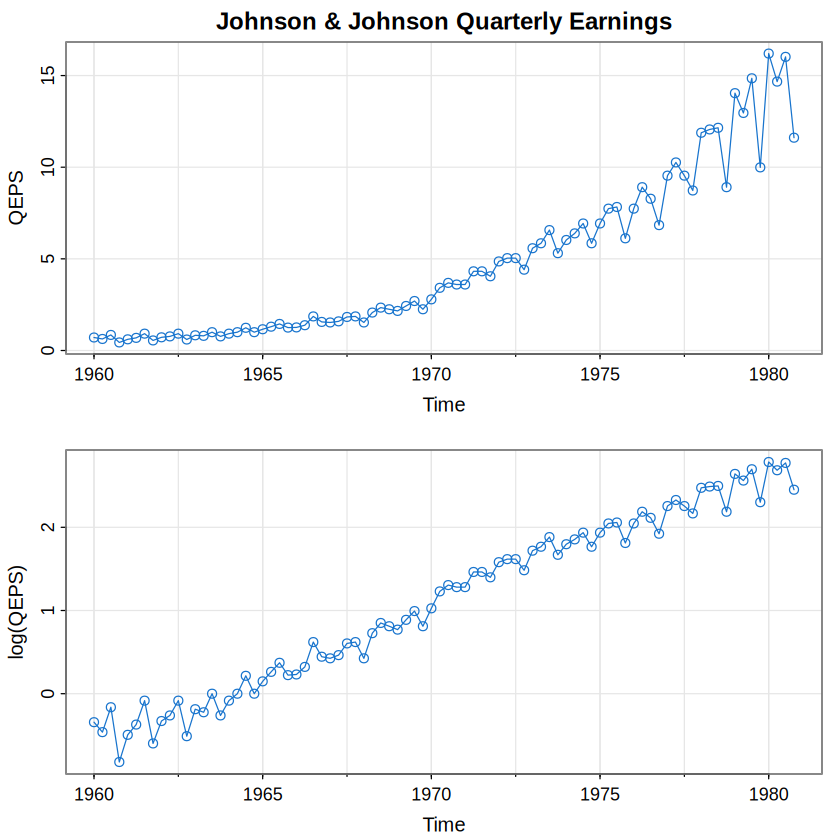

In [2]:
par(mfrow=2:1)
tsplot(jj, ylab="QEPS", type="o", col=4,
       main="Johnson & Johnson Quarterly Earnings")
tsplot(log(jj), ylab="log(QEPS)", type="o", col=4)
par(mfrow=c(1,1))

cat("Observations:", length(jj), "\n")
cat("Period:", start(jj)[1], "Q", start(jj)[2], "to", end(jj)[1], "Q", end(jj)[2], "\n")
cat("Original EPS range:", paste(round(range(jj),3),collapse=" to "), "\n")
cat("Logged EPS range:", paste(round(range(log(jj)),3),collapse=" to "), "\n")

In [3]:
# Compare annual proportional changes with annual log changes (lag = 4 quarters).
eps = as.numeric(jj)
yoy_return = eps[5:length(eps)]/eps[1:(length(eps)-4)] - 1
yoy_log_change = log(eps[5:length(eps)]) - log(eps[1:(length(eps)-4)])
print(head(data.frame(proportional_change=yoy_return,
                      log_change=yoy_log_change,
                      difference=yoy_return-yoy_log_change), 6))
cat("Correlation of changes:", cor(yoy_return,yoy_log_change), "\n")

  proportional_change log_change difference
1           -0.140845  -0.151806  0.0109609
2            0.095238   0.090972  0.0042663
3            0.082353   0.079137  0.0032156
4            0.250000   0.223144  0.0268564
5            0.180328   0.165792  0.0145356
6            0.115942   0.109699  0.0062431
Correlation of changes: 0.99632 


**Interpretation:** In the first plot, an upward earnings trend and increasing absolute fluctuations are visible; a repeated quarter-to-quarter pattern suggests a seasonal component. Logging compresses high earnings values more than low earnings values and makes multiplicative changes easier to compare. The printed first six rows give the *actual* historical year-over-year changes. A small `difference` means the log-change approximation is good for that observation; the correlation measures association between the two change series and does not measure their equality.

**Printed values:** `proportional_change` is $(x_t-x_{t-4})/x_{t-4}$; `log_change` is $\log(x_t)-\log(x_{t-4})$; `difference` is the simple change minus log change. Multiply either change by 100 to express it on a percentage-point scale. `Correlation of changes` near 1 means the two series move together; use `difference` to assess numerical approximation accuracy.


## Global temperature anomalies: two related series

A **temperature anomaly** is the difference between an observed temperature and a reference-period average, measured here in degrees Celsius. A positive anomaly indicates a warmer-than-baseline value, while a negative one indicates a cooler-than-baseline value. A **nonlinear trend** changes its rate of increase or decrease over time.

The land and sea surface series use a 1951–1980 reference average and extend through 2017. These values are differences from a baseline, not absolute temperatures. A plot can reveal co-movement and different rates of change, but cannot establish a cause on its own.


Land anomaly range: -1.1 2.5 
Sea anomaly range: -0.5 0.83 


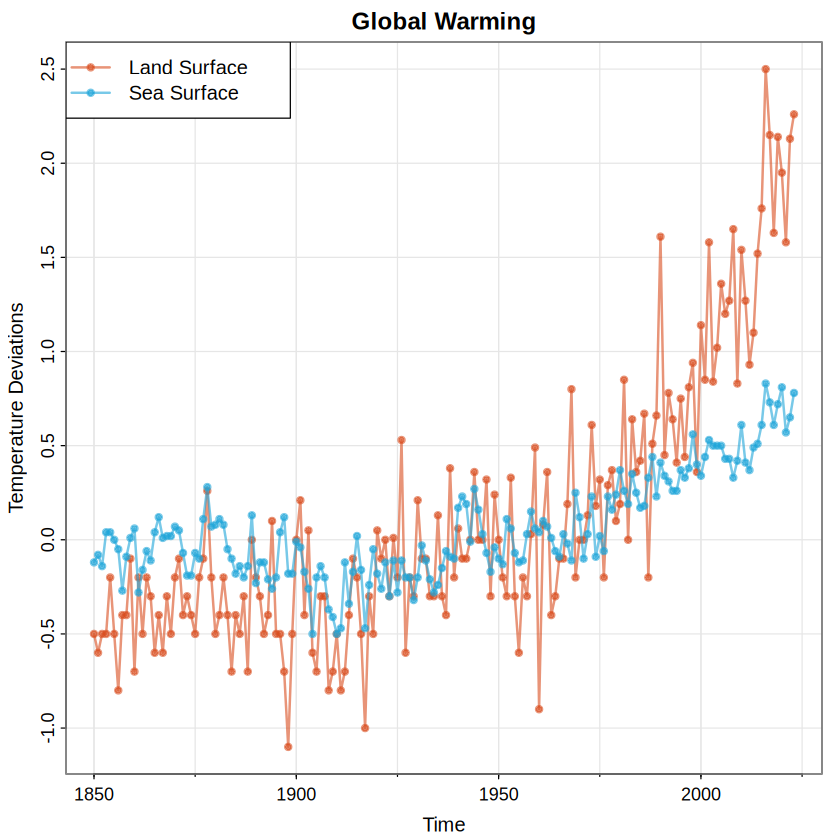

In [4]:
culer = c(rgb(.85,.30,.12,.6), rgb(.12,.65,.85,.6))
tsplot(gtemp_land, col=culer[1], lwd=2, type="o", pch=20,
       ylab="Temperature Deviations", main="Global Warming")
lines(gtemp_ocean, col=culer[2], lwd=2, type="o", pch=20)
legend("topleft", col=culer, lty=1, lwd=2, pch=20,
       legend=c("Land Surface", "Sea Surface"), bg="white")
cat("Land anomaly range:", range(as.numeric(gtemp_land),na.rm=TRUE), "\n")
cat("Sea anomaly range:", range(as.numeric(gtemp_ocean),na.rm=TRUE), "\n")

**Interpretation:** Compare the direction of each series, timing of rises and pauses, and relative variability. A positive anomaly means warmer than the reference-period average for that surface. Curvature or extended changes in slope indicate that one constant linear trend may be inadequate as a description. These plots do not establish what caused the changes.

**Printed ranges:** `Land anomaly range` and `Sea anomaly range` give the smallest and largest recorded temperature departures from the baseline in the corresponding historical dataset. Values above zero are warmer than the baseline and negative values are cooler; the range is *not* a confidence interval.


## DJIA closing prices: simple returns, log returns, and volatility

A **simple return** measures price change relative to the previous price. A **log return** measures the difference between natural logarithms of consecutive prices. **Volatility** describes the magnitude of return fluctuations; **volatility clustering** means large changes tend to occur close together in time, with calmer intervals between them.

For closing price $x_t$ and its preceding value $x_{t-1}$, the simple return is

$$
r_t=\frac{x_t-x_{t-1}}{x_{t-1}}=\frac{x_t}{x_{t-1}}-1.
$$

The log return is

$$
g_t=\log(x_t)-\log(x_{t-1})=\log(1+r_t).
$$

Here $r_t$ and $g_t$ are fractional changes (multiply by 100 to express them as percentages). Because $\log(1+r)=r-\frac{r^2}{2}+\cdots$, $g_t\approx r_t$ when $r_t$ is small. A price movement from 100 to 103 yields $r_t=0.03$ (3%) and $g_t=\log(1.03)\approx0.02956$ (about 2.956%). The DJIA data span April 2006–April 2016.


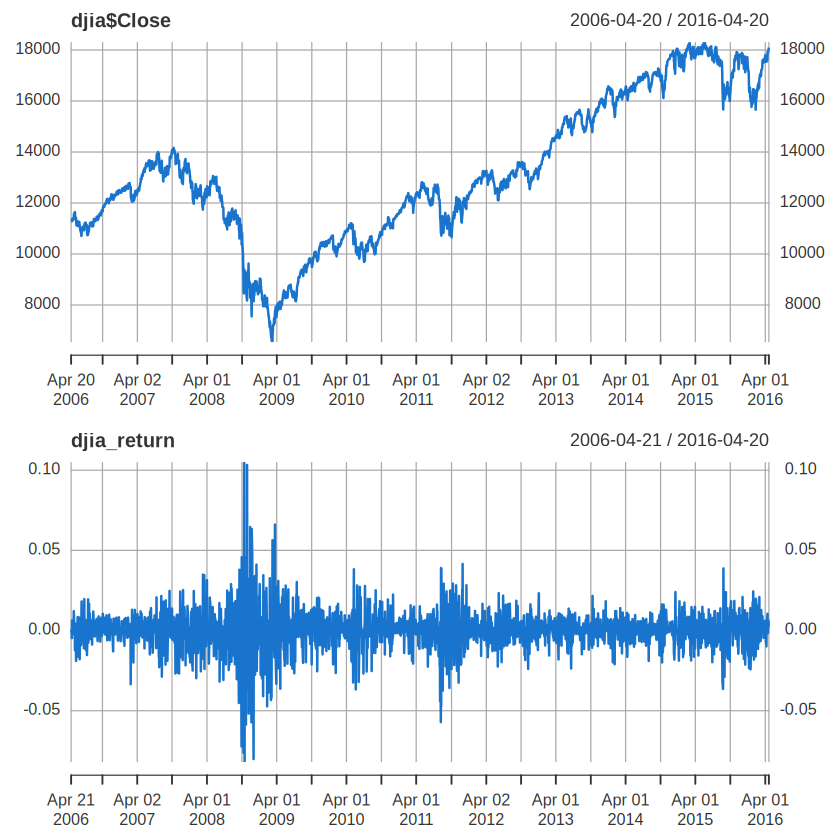

In [5]:
# Daily log returns and closing values
djia_return = diff(log(djia$Close))[-1]
par(mfrow=2:1)
plot(djia$Close, col=4)
plot(djia_return, col=4)
par(mfrow=c(1,1))

In [6]:
# Check actual numerical relationships on consecutive trading observations.
close = as.numeric(djia$Close)
simple_return = diff(close) / head(close,-1)
log_return = diff(log(close))
comparison = data.frame(simple_return=simple_return,
                        log_return=log_return,
                        approximation_error=simple_return-log_return)
print(head(comparison,6))
cat("Mean daily log return:", mean(log_return,na.rm=TRUE), "\n")
cat("SD of daily log returns:", sd(log_return,na.rm=TRUE), "\n")
cat("Max absolute simple/log difference:", max(abs(comparison$approximation_error),na.rm=TRUE), "\n")

  simple_return  log_return approximation_error
1    0.00040206  0.00040198          8.0805e-08
2   -0.00098083 -0.00098131          4.8133e-07
3   -0.00468144 -0.00469243          1.0992e-05
4    0.00631380  0.00629396          1.9849e-05
5    0.00246770  0.00246467          3.0398e-06
6   -0.00135033 -0.00135124          9.1251e-07
Mean daily log return: 0.00018558 
SD of daily log returns: 0.012101 
Max absolute simple/log difference: 0.0057199 


**Interpretation:** The level chart records index prices; the lower chart shows relative daily movements around a much smaller scale. A cluster of large positive and negative returns indicates a period of high *observed volatility*. The book identifies the 2008 crisis as one such period. The standard deviation summarizes dispersion over the entire sample, not how volatility evolves over time. The approximation error tends to be small for small daily changes. Large price levels are not equivalent to large returns.

**Printed values:** `Mean daily log return` is the arithmetic average of observed daily log returns (in decimal form); `SD of daily log returns` is their sample standard deviation; `Max absolute simple/log difference` gives the largest discrepancy between the two return definitions. The approximation is best when the daily simple return is close to zero.


## GDP growth: proportional difference versus log difference

**Growth rate** means the change in a series relative to its previous value. **Log differencing** takes the first difference of logarithms; for small changes it closely approximates the proportional growth rate.

$$
r_t=\frac{x_t-x_{t-1}}{x_{t-1}},\qquad g_t=\log(x_t)-\log(x_{t-1}).
$$

The series is quarterly: these are **quarter-over-quarter** rates, not annualized rates. In the R plots, agreement between the two lines/markers indicates that the approximation is accurate at the observed growth magnitudes.


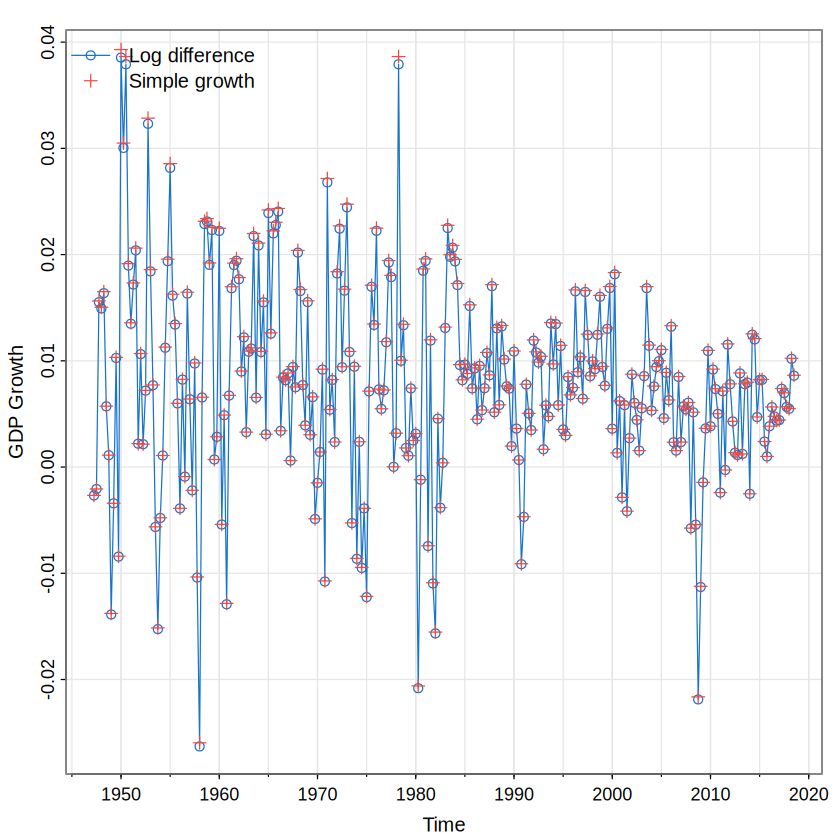

In [7]:
tsplot(diff(log(gdp)), type="o", col=4, ylab="GDP Growth") # diff-log
points(diff(gdp)/lag(gdp,-1), pch=3, col=2)             # actual return
legend("topleft", legend=c("Log difference", "Simple growth"),
       col=c(4,2), lty=c(1,NA), pch=c(1,3), bty="n")

In [8]:
# Compare corresponding numerical observations, omitting the first undefined growth.
gdp_value = as.numeric(gdp)
gdp_simple = diff(gdp_value)/head(gdp_value,-1)
gdp_log = diff(log(gdp_value))
print(head(data.frame(simple_growth=gdp_simple,
                      log_growth=gdp_log,
                      difference=gdp_simple-gdp_log),6))
cat("Mean absolute approximation error:",mean(abs(gdp_simple-gdp_log),na.rm=TRUE),"\n")

  simple_growth log_growth difference
1    -0.0026669 -0.0026705 3.5626e-06
2    -0.0020650 -0.0020671 2.1350e-06
3     0.0156421  0.0155210 1.2108e-04
4     0.0150426  0.0149305 1.1202e-04
5     0.0165066  0.0163718 1.3475e-04
6     0.0057290  0.0057126 1.6348e-05
Mean absolute approximation error: 7.4144e-05 


**Interpretation:** When the two plotted series nearly overlap, their numerical changes are similar at the scale of the plot. The mean absolute approximation error reports the average size of the difference, not a forecast error. For larger growth contractions or expansions, the simple and log changes can diverge more noticeably.

**Printed values:** Each `difference` is simple quarterly GDP growth minus the corresponding log difference. `Mean absolute approximation error` averages the absolute discrepancies; multiply by 100 to interpret it in percentage points. It does *not* measure forecasting accuracy.


## El Niño / SOI and fish recruitment: cycles across series

A **cycle** is a rise-and-fall pattern that recurs over time but may vary in duration or strength. Unlike seasonality, a cycle need not repeat at a fixed calendar interval. **SOI (Southern Oscillation Index)** is an atmospheric-pressure indicator associated with El Niño–Southern Oscillation. **Recruitment** here is an index representing new fish entering a population.

The monthly series may show shorter seasonal variation and slower cycles. Comparing their time plots helps identify patterns and possible timing differences, but visual similarity alone does not demonstrate causation.


SOI observations: 453 ; recruitment observations: 453 
SOI mean and SD: 0.080038 0.38275 
Recruitment mean and SD: 62.263 27.977 


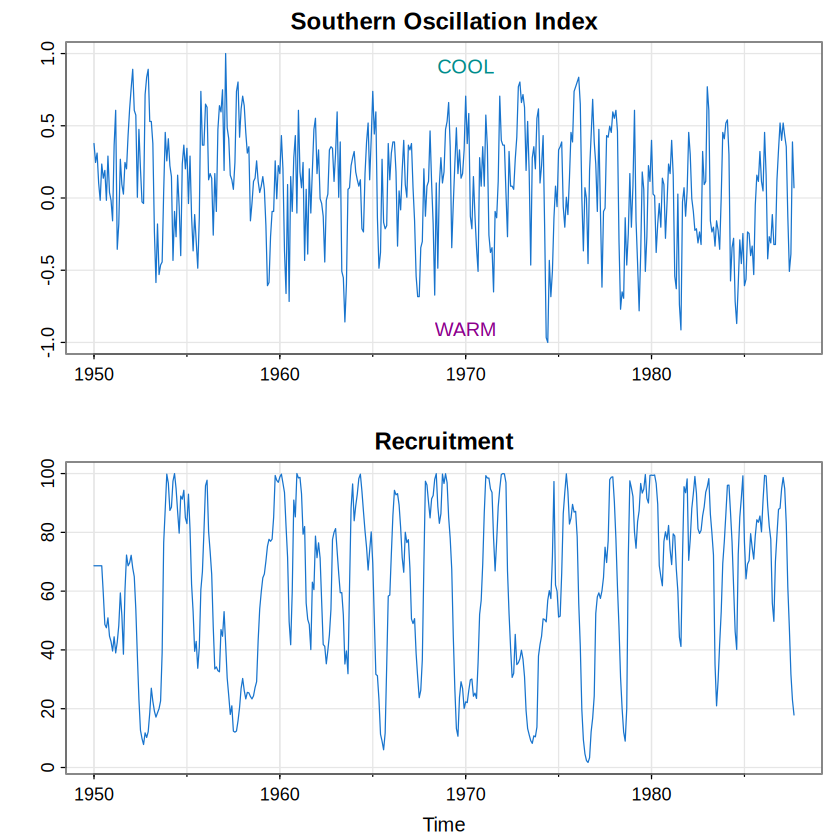

In [9]:
par(mfrow = c(2,1))
tsplot(soi, ylab="", xlab="", main="Southern Oscillation Index", col=4)
text(1970, .91, "COOL", col="cyan4")
text(1970,-.91, "WARM", col="darkmagenta")
tsplot(rec, ylab="", main="Recruitment", col=4)
par(mfrow=c(1,1))
cat("SOI observations:",length(soi),"; recruitment observations:",length(rec),"\n")
cat("SOI mean and SD:",mean(soi,na.rm=TRUE),sd(soi,na.rm=TRUE),"\n")
cat("Recruitment mean and SD:",mean(rec,na.rm=TRUE),sd(rec,na.rm=TRUE),"\n")

**Interpretation:** Look for repeating peaks and troughs, variation in how long cycles last, and whether changes in one series appear to precede changes in the other. Their vertical axes have different units, so comparing amplitudes directly is inappropriate. A phase or lag relationship would require a specific time-alignment analysis beyond these plots.

**Printed values:** The observation counts confirm the sample size; the mean gives the historical average of each series, and `SD` measures dispersion around that average in each series' own units. Comparing the two numerical SDs directly is not meaningful because the two indices use different scales.


## Predator–prey series: hare and lynx

**Predator–prey interaction** describes how changes in prey availability and predator abundance may affect one another. A **proxy variable** is an indirect measure used when the quantity of interest is unavailable; here, pelt counts are proxies for animal abundance.

A **lagged response** occurs when changes in one series appear after changes in another. Look for repeated peaks, troughs, and delays between hare and lynx series, while remembering that trapping and reporting may affect pelt counts.


Hare maximum: 152.65 ; Lynx maximum: 79.35 


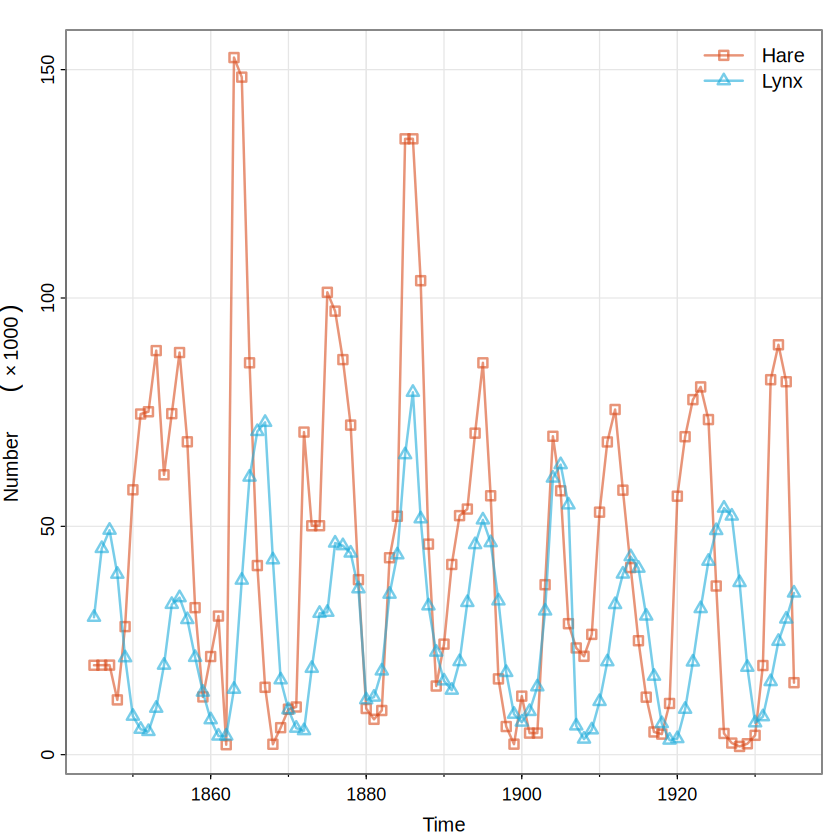

In [10]:
culer = c(rgb(.85,.30,.12,.6), rgb(.12,.67,.86,.6))
tsplot(Hare, col = culer[1], lwd=2, type="o", pch=0,
       ylab=expression(Number~~~(""%*% 1000)))
lines(Lynx, col=culer[2], lwd=2, type="o", pch=2)
legend("topright", col=culer, lty=1, lwd=2, pch=c(0,2),
       legend=c("Hare", "Lynx"), bty="n")
cat("Hare maximum:",max(Hare,na.rm=TRUE),"; Lynx maximum:",max(Lynx,na.rm=TRUE),"\n")

**Interpretation:** Inspect whether major lynx peaks occur later than hare peaks and how quickly counts rise and fall. Cyclic co-movement is compatible with a predator–prey relationship, but does not prove causation; the series measure collected pelts rather than directly counted animals.

**Printed values:** `Hare maximum` and `Lynx maximum` are the highest recorded pelt-count observations (in thousands in the plot). A maximum tells the peak magnitude, but not the peak year; identify the year by the time position of the plotted peak.


## fMRI responses: periodic stimulus and observed signals

**fMRI** is functional magnetic resonance imaging. The **BOLD (blood-oxygen-level-dependent) signal** is an indirect measure related to changing blood oxygenation. A **stimulus signal** indicates when an experimental input is on or off; a **period** is the time required for a pattern to complete one full repetition.

There are 128 measurements sampled every 2 seconds. The stimulus is on for 32 seconds and off for 32 seconds, giving a 64-second period, or $64/2=32$ samples per cycle. The square-wave overlay marks the stimulus schedule; it does not itself measure the brain response.


Stimulus samples: 128 ; complete on/off cycles: 4 


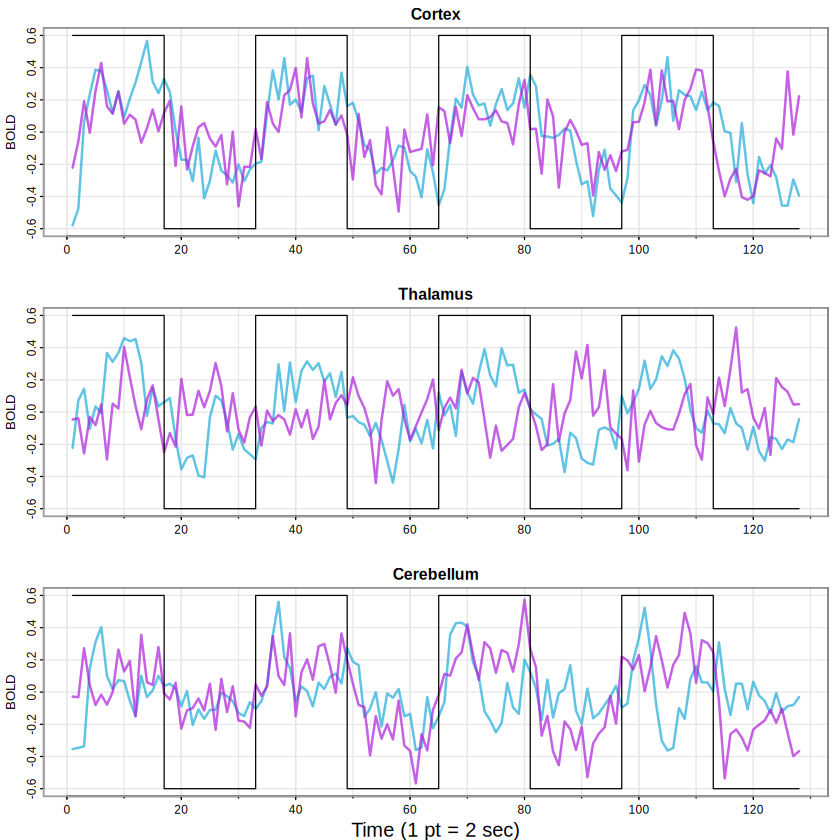

In [11]:
par(mfrow=c(3,1))
culer = c(rgb(.12,.67,.85,.7), rgb(.67,.12,.85,.7))
u = rep(c(rep(.6,16), rep(-.6,16)), 4) # stimulus signal
tsplot(fmri1[,4], ylab="BOLD", xlab="", main="Cortex", col=culer[1],
       ylim=c(-.6,.6), lwd=2)
lines(fmri1[,5], col=culer[2], lwd=2)
lines(u, type="s")
tsplot(fmri1[,6], ylab="BOLD", xlab="", main="Thalamus", col=culer[1],
       ylim=c(-.6,.6), lwd=2)
lines(fmri1[,7], col=culer[2], lwd=2)
lines(u, type="s")
tsplot(fmri1[,8], ylab="BOLD", xlab="", main="Cerebellum",
       col=culer[1], ylim=c(-.6,.6), lwd=2)
lines(fmri1[,9], col=culer[2], lwd=2)
lines(u, type="s")
mtext("Time (1 pt = 2 sec)", side=1, line=1.75)
par(mfrow=c(1,1))
cat("Stimulus samples:",length(u),"; complete on/off cycles:",length(u)/32,"\n")

**Interpretation:** Compare whether peaks and troughs repeat near the stimulus period across the cortical, thalamic, and cerebellar measurements. The extract describes a clearer pattern in cortex and less obvious responses in some other regions. Visual agreement is not a significance test; BOLD response delays and noise prevent treating perfect alignment as a requirement.

**Printed values:** `Stimulus samples = 128` and `complete on/off cycles = 4` verify the signal duration. Every block of 16 samples represents 32 seconds; one on/off pair covers 64 seconds. The stepped line shows the experimental stimulus, not an estimated fMRI response.


## White noise and three-point moving-average filtering

**White noise** is a time series whose values have no linear correlation across distinct times. With a constant mean of zero and variance $\sigma_w^2$, its defining conditions are

$$
E[w_t]=0,\qquad \operatorname{Var}(w_t)=\sigma_w^2,\qquad \operatorname{Cov}(w_t,w_s)=0\quad (t\ne s).
$$

$w_t$ is the random noise at time $t$; $E[\cdot]$ is expected value, $\operatorname{Var}$ is variance, and $\operatorname{Cov}$ is covariance. **Gaussian white noise** additionally uses normally distributed noise. White noise need not be Gaussian or independent to be uncorrelated.

A **moving-average filter** replaces each point with a weighted average of nearby points to suppress short, rapid fluctuations. A **centered** three-point filter uses one observation before and one after time $t$:

$$
v_t=\frac{w_{t-1}+w_t+w_{t+1}}{3}.
$$

For $w_{t-1}=1$, $w_t=2$, and $w_{t+1}=3$, the result is $v_t=2$. If the original noise is uncorrelated,

$$
\operatorname{Var}(v_t)=\frac{\sigma_w^2+\sigma_w^2+\sigma_w^2}{9}=\frac{\sigma_w^2}{3}.
$$

For unit-variance noise, the theoretical variance falls from 1 to $1/3$. Adjacent filtered values overlap in the observations they average, making the resulting values correlated.


Original mean: -0.062781 ; filtered mean: -0.060804 
Original sample variance: 0.9338 ; filtered sample variance: 0.32172 
Expected variances: 1 and 0.33333 
Missing filtered endpoints: 2 


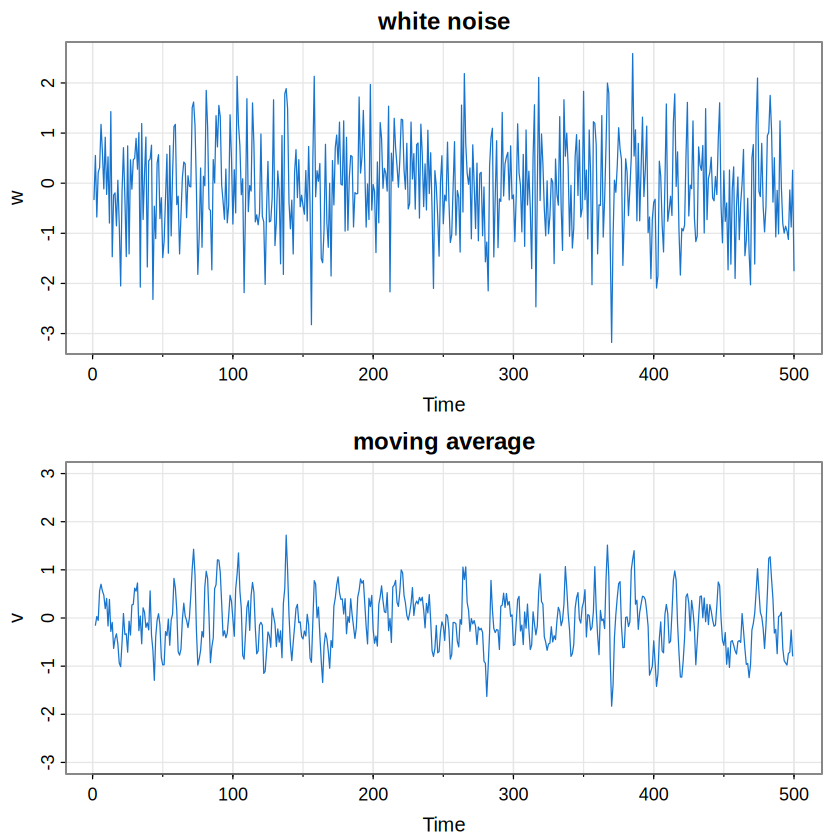

In [12]:
set.seed(101)
par(mfrow=2:1)
w = rnorm(500)                             # 500 N(0,1) variates
v = filter(w, sides=2, filter=rep(1/3,3)) # moving average
tsplot(w, col=4, main="white noise")
tsplot(v, ylim=c(-3,3), col=4, main="moving average")
par(mfrow=c(1,1))
cat("Original mean:",mean(w),"; filtered mean:",mean(v,na.rm=TRUE),"\n")
cat("Original sample variance:",var(w),"; filtered sample variance:",var(v,na.rm=TRUE),"\n")
cat("Expected variances: 1 and",1/3,"\n")
cat("Missing filtered endpoints:",sum(is.na(v)),"\n")

**Interpretation:** Smoothing removes some rapid variation. The printed sample variances should be *near* 1 and 1/3, not necessarily equal to them, because only 500 observations were simulated. The centered filter returns `NA` at the first and last positions because the full three-point neighborhood is unavailable. The `na.rm=TRUE` argument excludes those boundary values when computing statistics.

**Printed values:** `Original mean` and `filtered mean` summarize the two observed realizations; `Original sample variance` and `filtered sample variance` can be compared to theoretical values 1 and $1/3$. Their ratio quantifies variance reduction in this simulation. `Missing filtered endpoints = 2` occurs because the centered average requires a preceding and following observation.


## Autoregression: recursively generated oscillations

An **autoregressive (AR) model** expresses the current value as a weighted combination of earlier values plus a new random disturbance. The **order** is the number of lagged observations included: **AR(2)** uses $x_{t-1}$ and $x_{t-2}$. A **lag** is the number of time steps back; the **innovation** $w_t$ is the unpredictable new contribution at time $t$.

$$
x_t=1.5x_{t-1}-0.75x_{t-2}+w_t,\qquad w_t\sim N(0,1).
$$

The coefficients 1.5 and $-0.75$ determine how the past two values affect the current value; $N(0,1)$ denotes a normal distribution with mean zero and variance one. Starting with $x_{-1}=x_0=0$,

$$
x_1=w_1,\qquad x_2=1.5w_1+w_2,
$$

$$
x_3=1.5x_2-0.75x_1+w_3=1.5w_1+1.5w_2+w_3.
$$

**Manual example:** if $w_1=1$, $w_2=0$, and $w_3=-1$, then $x_1=1$, $x_2=1.5$, and $x_3=0.5$. The actual simulation uses different random draws. A **burn-in** or **warm-up** removes early observations affected by artificial starting conditions; the first 50 simulated values are discarded below.


Retained observations: 250 
Mean: -0.10217 ; SD: 3.2708 
Observed range: -8.4411 8.8113 


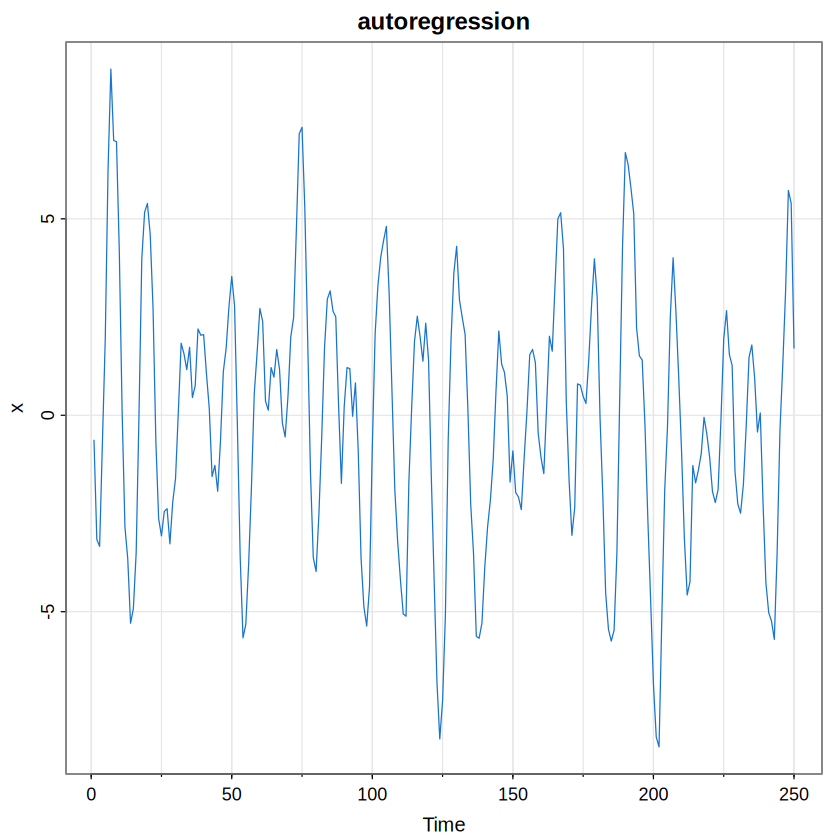

In [13]:
set.seed(90210)
w = rnorm(250 + 50) # 50 extra to avoid startup problems
x = filter(w, filter=c(1.5,-.75), method="recursive")[-(1:50)]
tsplot(x, main="autoregression", col=4)
cat("Retained observations:",length(x),"\n")
cat("Mean:",mean(x),"; SD:",sd(x),"\n")
cat("Observed range:",range(x),"\n")

**Interpretation:** Rather than drawing each $x_t$ independently, the recursion uses the preceding two values and a random innovation. This creates runs and approximate oscillations; the book reports a pseudo-period of about 12 observations for this parameter choice. It is *not* a fixed, noise-free 12-step cycle. The calculated mean and standard deviation summarize this realization, not the exact model expectations.

**Printed values:** `Retained observations = 250` confirms that the first 50 simulated observations were discarded. `Mean`, `SD`, and `Observed range` are sample summaries, so they vary across simulations without a fixed seed. The characteristic oscillation comes from the AR coefficients $1.5$ and $-0.75$; the noise prevents perfect repetition.


## Random walk with and without drift

A **random walk** adds a new random shock to the previous value. Its shocks accumulate over time, so departures from an earlier level can persist. **Drift** ($\delta$) is a constant expected change added at each time step. With zero drift, there is no systematic upward or downward expected step.

$$
x_t=\delta+x_{t-1}+w_t,\qquad x_0=0.
$$

Repeated substitution gives

$$
x_t=\delta t+\sum_{j=1}^{t}w_j.
$$

Here $j$ indexes the innovations being summed, and $t$ is the number of elapsed steps. Assuming independent shocks with mean zero and variance $\sigma_w^2$,

$$
E[x_t]=\delta t,\qquad \operatorname{Var}(x_t)=t\sigma_w^2.
$$

At $t=200$ and $\delta=0.3$, the expected level is $0.3(200)=60$, although the observed simulated value generally differs. Dashed lines represent expected drift paths, not confidence intervals.


Without drift final level: 16.468 
With drift final level: 76.468 
Theoretical expected drifted level after 200 steps: 60 
Exact difference between paths after 200 steps: 60 


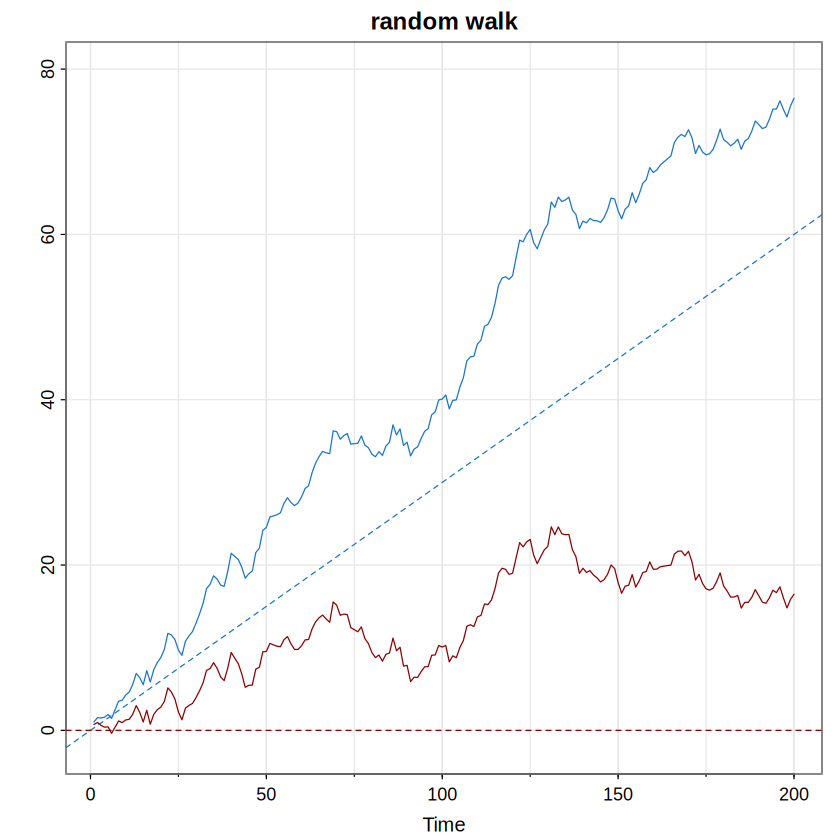

In [14]:
set.seed(314159265)              # so you can reproduce the results
w = rnorm(200); x = cumsum(w) # random walk
wd = w +.3;
xd = cumsum(wd)                # random walk with drift
tsplot(xd, ylim=c(-2,80), main="random walk", ylab="", col=4)
abline(a=0, b=.3, lty=2, col=4) # plot drift
lines(x, col="darkred")
abline(h=0, col="darkred", lty=2)
cat("Without drift final level:",tail(x,1),"\n")
cat("With drift final level:",tail(xd,1),"\n")
cat("Theoretical expected drifted level after 200 steps:",.3*200,"\n")
cat("Exact difference between paths after 200 steps:",tail(xd-x,1),"\n")

**Interpretation:** Because both paths use the **same** innovations, $x_t^{\text{drift}}-x_t^{\text{no drift}}=0.3t$ exactly. A random walk accumulates shocks rather than automatically returning to zero. Its uncertainty increases with time; a visible upward sample path on its own is not proof of a nonzero deterministic drift. The plot uses the axis range given ; values outside that range would be clipped.

**Printed values:** `Without drift final level` is $\sum_{t=1}^{200}w_t$; `With drift final level` is $60+\sum_{t=1}^{200}w_t$; `Theoretical expected drifted level` is $200(0.3)=60$. `Exact difference between paths` is 60 because the same noise sample was used for both paths.


## Periodic signal plus white noise

A **signal** is the structured component of a series; **noise** is its unpredictable component. A **sinusoidal signal** repeats in a wave-like pattern. Its **amplitude** sets the height of the oscillation, **frequency** counts cycles per observation, **period** counts observations per cycle, and **phase** controls horizontal positioning.

$$
s_t=A\cos(2\pi\omega t+\phi),\qquad T=\frac{1}{\omega}.
$$

Here $A$ is amplitude, $\omega$ is frequency, $\phi$ is phase shift in radians, and $T$ is the period. Adding noise $w_t$ gives $x_t=s_t+w_t$. For the example,

$$
x_t=2\cos\left(\frac{2\pi(t+15)}{50}\right)+w_t.
$$

Thus $A=2$, $T=50$, $\omega=1/50$, and $\phi=2\pi(15/50)=0.6\pi$. At $t=1$, the noiseless value is $2\cos(32\pi/50)$. **Signal-to-noise ratio (SNR)** compares signal strength with noise strength. Using the amplitude-to-noise-SD convention gives $2/1=2$ for noise SD 1 and $2/5=0.4$ for noise SD 5; other SNR definitions are possible.


Signal range: -2 2 
Signal variance: 2.004 
Observed SD with low noise: 1.6929 
Observed SD with high noise: 5.2126 
Amplitude/noise-SD ratios: low noise = 2 ; high noise = 0.4 


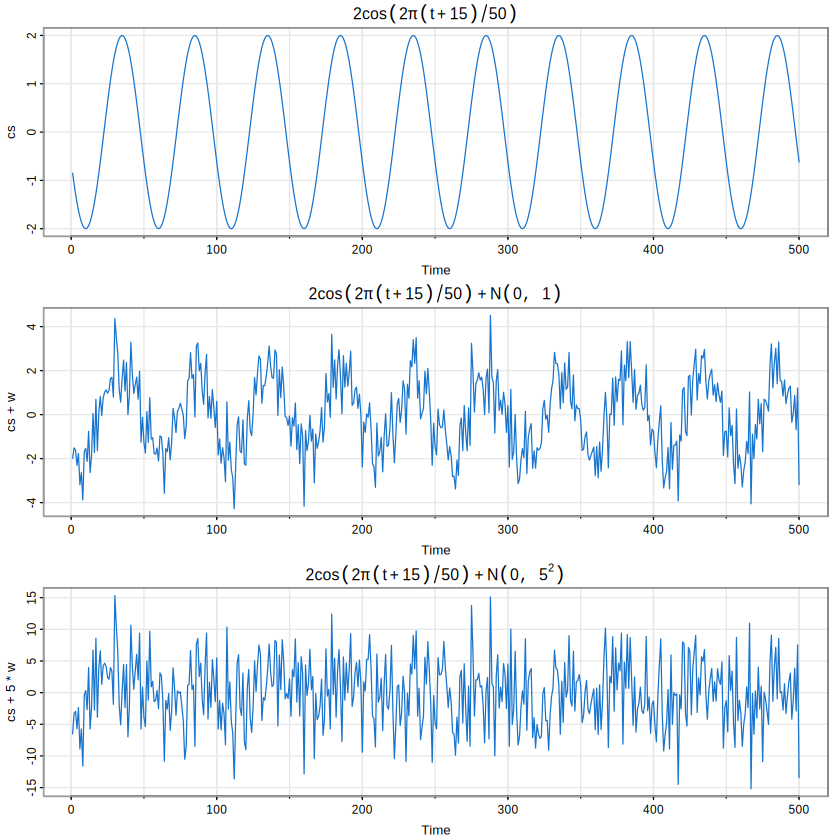

In [15]:
set.seed(202)
t = 1:500
cs = 2*cos(2*pi*(t+15)/50) # signal
w = rnorm(500)             # noise
par(mfrow=c(3,1))
tsplot(cs, col=4, main=expression(2*cos(2*pi*(t+15)/50)))
tsplot(cs+w, col=4, main=expression(2*cos(2*pi*(t+15)/50)+N(0,1)))
tsplot(cs+5*w,col=4, main=expression(2*cos(2*pi*(t+15)/50)+N(0,5^2)))
par(mfrow=c(1,1))
cat("Signal range:",range(cs),"\n")
cat("Signal variance:",var(cs),"\n")
cat("Observed SD with low noise:",sd(cs+w),"\n")
cat("Observed SD with high noise:",sd(cs+5*w),"\n")
cat("Amplitude/noise-SD ratios: low noise =",2/1,"; high noise =",2/5,"\n")

**Interpretation:** The first panel shows ten complete cycles in 500 observations. Adding noise with SD 1 leaves the periodic structure fairly visible; SD 5 makes it harder to distinguish the signal from random changes. The printed SD of the *combined series* includes both signal and noise and should not be mistaken for the noise SD. The use of the same standardized random innovations in both noisy plots makes the comparison reproducible.

**Printed values:** `Signal range` describes the noiseless cosine values; `Signal variance` is the variation due to the deterministic oscillation. `Observed SD with low noise` and `Observed SD with high noise` measure variability of the *entire signal-plus-noise series*. They are distinct from the noise SDs 1 and 5. `Amplitude/noise-SD ratios` are 2 and 0.4, explaining why the periodic structure becomes harder to see in the last panel.


## Reference

Shumway, R. H., & Stoffer, D. S. (2019). *Time Series: A Data Analysis Approach Using R*. Chapman & Hall/CRC Press. Chapter 1, “Time Series Elements.”
